In [34]:
import xcs_code_stockpile as xcs
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [35]:
proposal_number = 101927227  # noqa
run = 49  # noqa

In [36]:
h5 = xcs.load_smalldata(run, proposal_number)
h5dict = xcs.H5Dictionary(
    stack='/jungfrau1M/ROI_area',
    i0=lambda h5: h5['diodeGon/channels'][..., 0],
    laser_on='evr/code_41',
    delay='scan/awg_delay_ns_delay'
)

In [37]:
metadata = xcs.create_metadata(h5, run, h5dict, roi=None)
valid = xcs.sensible_filter(metadata, 0.5, 99.5, 0.5, 99.5)

In [38]:
rois = [
    (slice(70, 80), slice(185, 195)),
    (slice(70, 80), slice(165, 175))
]

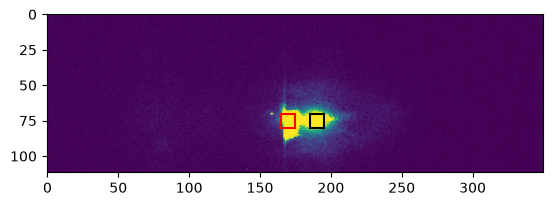

In [39]:
xcs.plot_detector_image(h5, h5dict, samplerate=100)
roi_colors = ['black', 'red']
for i, roi in enumerate(rois):
    plt.plot([roi[1].start, roi[1].stop], [roi[0].start, roi[0].start], color=roi_colors[i])
    plt.plot([roi[1].start, roi[1].stop], [roi[0].stop, roi[0].stop], color=roi_colors[i])
    plt.plot([roi[1].start, roi[1].start], [roi[0].start, roi[0].stop], color=roi_colors[i])
    plt.plot([roi[1].stop, roi[1].stop], [roi[0].start, roi[0].stop], color=roi_colors[i])

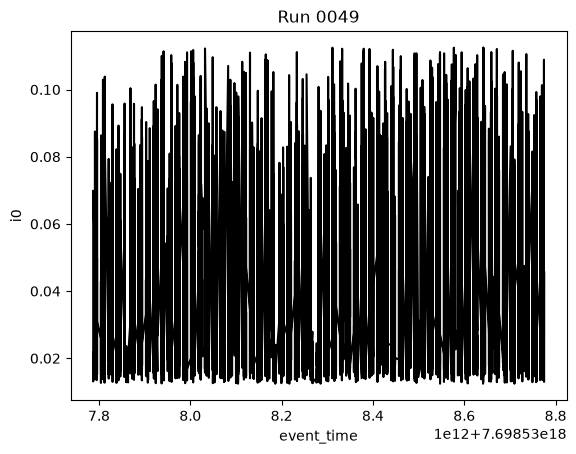

In [40]:
xcs.plot_i0_vs_time(metadata, valid).show()

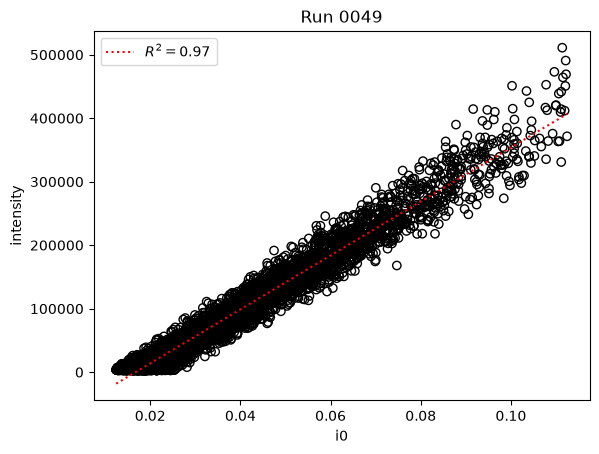

In [41]:
xcs.plot_intensity_vs_i0(metadata, valid).show()

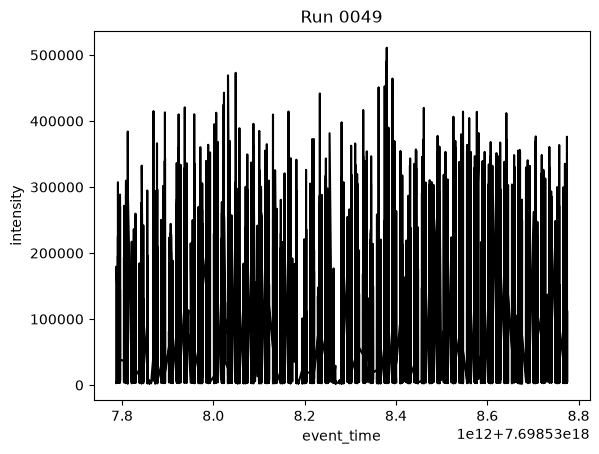

In [42]:
xcs.plot_intensity_vs_time(metadata, valid).show()

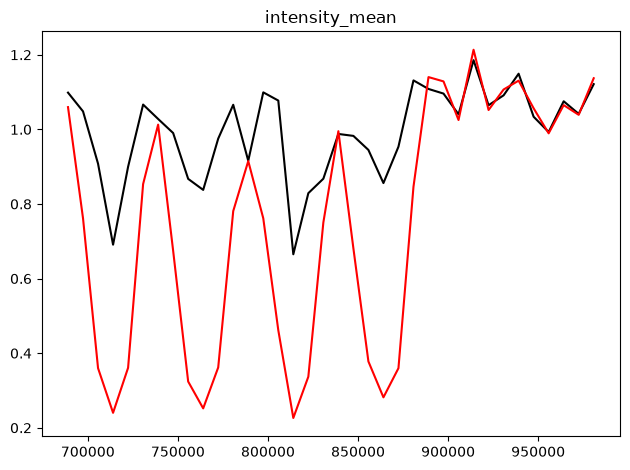

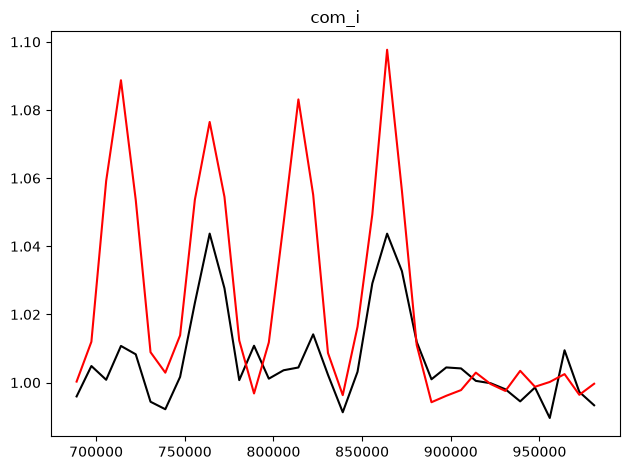

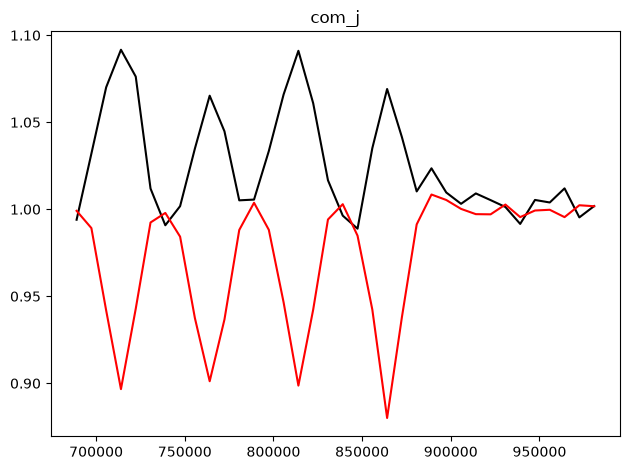

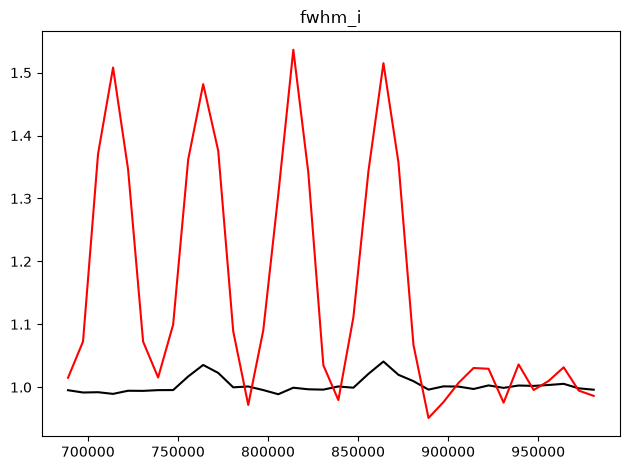

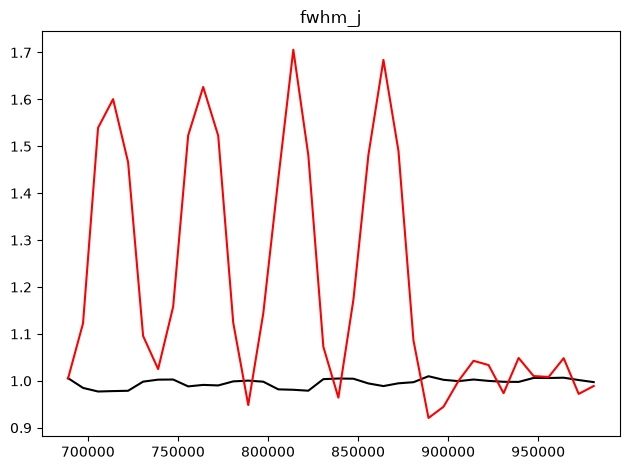

In [43]:
for i, tag in enumerate(['intensity_mean', 'com_i', 'com_j', 'fwhm_i', 'fwhm_j']):
    fig, ax = plt.subplots(1, 1)
    for j, (roi, color) in enumerate(zip(rois, roi_colors)):
        trxrd = xcs.calc_trxrd_stats(h5, h5dict, metadata, valid, 4169*2, roi=roi)

        ax.plot(trxrd.index, trxrd[f'on_{tag}']/trxrd[f'off_{tag}'], color=color)
    ax.set_title(tag)
    fig.tight_layout()
    plt.show()